# Projet Data Mining — Enquête collective et narratif caché

**UE Data Mining — M2 Data Science, 2026–2027**  
**Groupe :** M2 Data Science — Projet Data Mining 
**Membres mentionnés dans le projet :** Leon BYTYQI, Irfat FEJZULLAHU, Fares FERCHICHE, Max M’BEY, Mustapha Harmoush et Nour Ben Mansour 

Notre objectif est de retrouver le récit caché dans quatre ensembles de **données entièrement fictives**. Nous présentons d'abord les méthodes et les résultats des six enquêtes, puis leurs recoupements et notre hypothèse collective. Une anomalie statistique ou administrative n'est pas automatiquement la preuve d'une action intentionnelle.

## 1. La question que nous cherchons à résoudre

Au départ, les fichiers semblent parler de sujets différents : dossiers administratifs, entreprises, soins médicaux, écologie, transport et documents. En les étudiant séparément, nous avons trouvé plusieurs particularités. Notre objectif est maintenant de voir si elles sont liées.

Notre question est la suivante : **les données révèlent-elles un circuit organisé autour de la collecte biologique, du transport restreint et d'un programme médical confidentiel ?** Et si oui, qu'est-ce qui est démontré par les fichiers et qu'est-ce qui reste une hypothèse ?

On sépare donc trois niveaux : **les correspondances exactes** entre identifiants, **les rapprochements par dates ou par résultats**, et **les affirmations contenues dans des documents**. Ces trois niveaux n'ont pas la même force.

## 2. Notre méthode

Nous avons réparti les données en six enquêtes : dossiers administratifs, registres et réseaux, santé, écologie, logistique, puis textes et signaux. Pour chaque domaine, nous avons contrôlé la qualité des fichiers, choisi des **méthodes de fouille de données adaptées**, produit des tableaux ou graphiques et examiné les résultats avec leurs limites.

Nous avons ensuite croisé les domaines de deux façons : **jointures par identifiants exacts** lorsque les clés existent, et **rapprochements temporels documentés** lorsqu'il n'existe pas de clé commune. Les deux types de lien ne constituent pas le même niveau de preuve.

### Comment lire les analyses

Les **tableaux et figures qui suivent sont des résultats calculés**, intégrés dans ce rapport pour être consultés sans exécuter de code. Les méthodes détaillées restent accessibles dans les notebooks individuels et les calculs du rapport peuvent être régénérés par le script Python fourni avec le projet. Les fichiers de données d'origine ne sont pas modifiés.

# Partie I — Les six enquêtes

## Enquête 1 — Dossiers et coordination

**Question.** Quels parcours sont habituels dans les dossiers réglementaires et les demandes d'accès, et quels dossiers s'en écartent ?

**Méthodes techniques.** Après dédoublonnage et normalisation des dates, activités et statuts, chaque dossier est traité comme une **trace d'événements ordonnés**. L'analyse individuelle applique du *process mining* : calcul des **transitions directement successives** entre activités, **matrices de transitions** et graphes de processus avec filtrage des liens. Les durées sont comparées par catégorie de dossier et les valeurs atypiques sont recherchées à partir des **quantiles et de règles de séquencement** (autorisation, revue technique, clôture). Les clés `case_number`, `access_case_number`, `site_code` et `related_shipment_number` servent aux croisements.

**Dans ce rapport :** effectifs, durées médianes et fréquence des étapes ; les matrices de transitions et les alertes détaillées figurent dans `01_dossiers_et_coordination.ipynb`.

**Tableau — Volumes et durées des dossiers**

| Type | Événements | Dossiers | Durée médiane (jours) | Dates manquantes |
| --- | --- | --- | --- | --- |
| Réglementaires | 232 | 40 | 18.0 | 0 |
| Accès aux sites | 412 | 60 | 17.0 | 0 |

**Figure — Étapes enregistrées dans les dossiers d'accès**

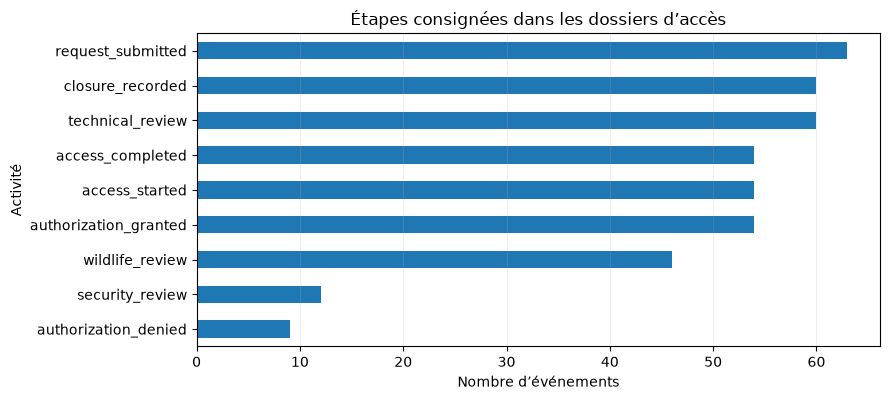

**Résultats et interprétation.** Nous retrouvons **40 dossiers réglementaires** (232 événements) et **60 demandes d’accès** (412 événements). Les durées médianes sont respectivement **18** et **17 jours**. Trois accès (`ACC-2021-0010`, `ACC-2023-0013`, `ACC-2024-0015`) sont notamment signalés dans l'enquête individuelle parce qu'aucune nouvelle revue technique n'est enregistrée après la dernière demande. Cela peut être normal si une revue antérieure reste valable.

**Limite.** Un dossier inhabituel ou une étape manquante dans les fichiers ne permet pas de conclure à une irrégularité. Le rôle de cette partie est d'identifier des **dates, sites et identifiants** qui pourront être rapprochés des autres domaines.

## Enquête 2 — Registres, personnes et réseau d'organisations

**Question.** Quelles personnes et organisations sont reliées, et quelles successions d'identités ou de fonctions méritent d'être examinées ?

**Méthodes techniques.** Les noms sont normalisés (casse, accents, civilités, ponctuation), puis la *résolution d'entités* combine un **blocage des paires candidates** (initiales et périodes de naissance) et `RapidFuzz.token_sort_ratio` (**seuil de candidature ≥ 85/100**). Les paires sont classées *certaines*, *probables* ou *incertaines* selon les attributs concordants et contradictoires (naissance, fonction, région, chronologie). Un échantillon de **30 paires** a fait l'objet de jugements documentés dans l'enquête individuelle. Un **graphe multitype** (personnes, organisations, institutions, établissements) est étudié avec NetworkX : **degré, intermédiarité, composantes connexes, communautés de Louvain et modularité**. La robustesse est testée en retirant les fusions seulement probables.

**Dans ce rapport :** jointure exacte licence–consultation et graphe simplifié des mandats ; les fusions d'entités et le graphe multitype complet restent dans `02_registres_et_reseau.ipynb`.

Licence ancienne :

**Tableau — Licence médicale retrouvée dans les registres**

| license_number | professional_name | license_issue_date | license_status |
| --- | --- | --- | --- |
| LIC-VLN-MED-1001 | Emil Warden | 1895-07-01 | active |

Nombre de consultations utilisant cette licence : 147  
Période : 2015-09-21T09:15:00 → 2025-06-20T13:15:00

**Tableau — Organisations ayant le plus de liens déclarés**

| Organisation (n° registre) | Nombre de personnes reliées |
| --- | --- |
| O: REG-VLN-01002 | 10 |
| O: REG-AVL-01007 | 9 |
| O: REG-VLN-01021 | 9 |
| O: REG-VLN-01023 | 9 |
| O: REG-VLN-01005 | 9 |
| O: REG-VLN-01004 | 9 |
| O: REG-AVL-01009 | 8 |
| O: REG-NDH-01011 | 8 |

**Figure — Organisations reliées aux dirigeants par les mandats déclarés**

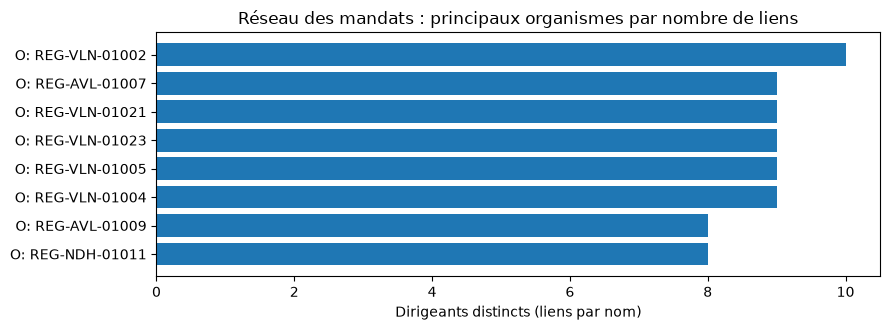

**Résultats.** Une licence d'**Emil Warden**, délivrée en **1895**, apparaît dans **147 consultations de 2015 à 2025**. L'analyse de succession des organismes fait aussi apparaître deux chaînes : **Vann → Warden → Vosmere → Meridian** et **Varlan → Bell → Marot → Vale**. La structure du réseau reste globalement similaire lorsque les fusions probables sont retirées, même si certains liens de pont disparaissent.

**Limite.** Ces liens administratifs ne démontrent ni l'identité réelle du praticien, ni la continuité biologique des personnes désignées dans les archives. Les jugements sur les 30 paires doivent être interprétés à la lumière de leur petit effectif et de l'assistance déclarée à leur examen.

## Enquête 3 — Données médicales et rythmes cardiaques

**Question.** Certains profils médicaux s'écartent-ils du reste des patients de manière répétée ?

**Méthodes techniques.** Après dédoublonnage, nettoyage numérique et contrôle des unités, les pouls **apical et périphérique** sont rapprochés par `(patient_number, encounter_number)` avec contrôle de cardinalité `one_to_one`. Les écarts sont résumés par patient ; les valeurs atypiques sont repérées par la **règle des quartiles (IQR)**. L'enquête individuelle applique ensuite **StandardScaler puis K-Means** sur trois variables (âge, écart de pouls médian, débit cardiaque `CARDOUT` médian), avec choix de **K entre 2 et 6 par silhouette**. Elle recherche aussi des **associations de procédures** (support, lift). Enfin, une **autocorrélation temporelle par canal** permet d'estimer les périodes des motifs cardiaques.

**Dans ce rapport :** les résultats calculés des paires de pouls et des deux périodicités de `PAT-31065` sont présentés. Les tests de clustering et d'associations sont détaillés dans `03_sante.ipynb`.

Patients 240 — consultations 1067 — observations 17734 — procédures 310  
Paires de pouls comparables : 1017 patients : 240  
Écart médian (bpm) : 2.7

**Tableau — Périodes estimées pour les deux enregistrements cardiaques**

| Enregistrement | Canal | Période (s) | Cycles/min |
| --- | --- | --- | --- |
| CRD-410038 | A | 0.90 | 66.37 |
| CRD-410038 | B | 0.61 | 98.68 |
| CRD-410005 | A | 0.90 | 66.67 |
| CRD-410005 | B | 0.60 | 100.00 |

**Figure — PAT-31065 : périodicités cardiaques estimées par autocorrélation**

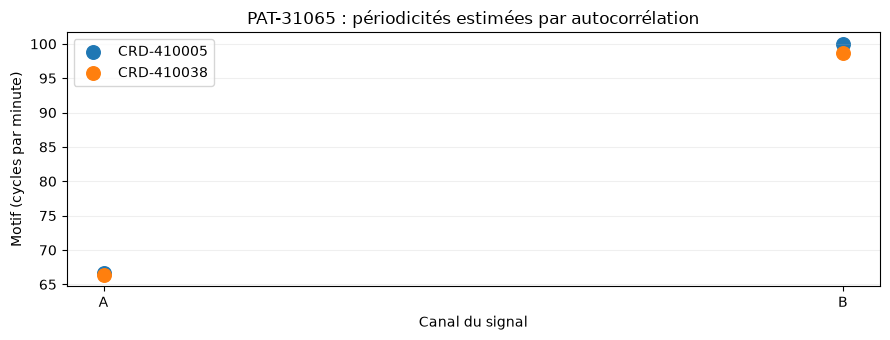

**Résultats et interprétation.** Dans l'enquête complète, **1 017 paires de pouls** sont comparables et **50 écarts** sont signalés par la règle statistique retenue, chez **18 patients**. Pour `PAT-31065`, les deux acquisitions donnent un motif autour de **66–67 cycles/min sur le canal A** et **99–100 cycles/min sur le canal B**. `CLN-510027` mentionne deux zones de contraction comme **hypothèse d'imagerie**. Une autre note (`CLN-510025`) propose un lien avec **Elias Voss**.

**Limites.** Il s'agit de motifs dans des signaux synthétiques, pas d'un diagnostic ni d'une preuve d'anatomie non humaine. Le rapprochement avec Elias Voss ne concorde pas avec les dates de naissance renseignées : **1975** contre **1961**. Ces contradictions restent visibles.

## Enquête 4 — Écologie, capteurs et accès aux sites

**Question.** Les interventions sur les sites sont-elles associées à des variations d'activité des chauves-souris, une fois la saisonnalité et la qualité du suivi prises en compte ?

**Méthodes techniques.** L'effort d'observation est normalisé en **chauves-souris par heure**. L'analyse individuelle reconstitue, pour chaque accès `access_started`, une fenêtre de **trois mois avant et trois mois après**, en excluant le mois d'intervention ; **39 accès sur 54** possèdent une fenêtre complète. La variation médiane est calculée d'abord brute, puis **corrigée par une référence saisonnière propre au site** (calculée hors fenêtre). Des sites comparables sont sélectionnés selon leurs caractéristiques et observés aux mêmes dates : **37 accès disposent de comparateurs, dont 11 pour Horizon**. Les différences relatives et une analyse de sensibilité par site limitent le poids des interventions répétées.

**Dans ce rapport :** lecture du tableau exporté `exports/ecologie/tableaux/comparaison_acces.csv` et visualisation des variations corrigées ; les capteurs, la météo et les comparateurs sont examinés dans `notebooks/04_ecologie_analyse.ipynb` (avec son notebook de nettoyage).

Sites : 64 relevés : 4992 accès avec fenêtre complète : 39  
Avec sites comparables : 37 dont Horizon : 11

**Tableau — Comparaison des accès après correction saisonnière**

| groupe | acces | sites | variation_saisonniere_mediane | comparateurs_disponibles |
| --- | --- | --- | --- | --- |
| Autres organisations | 26 | 26 | -0.002 | 26 |
| Horizon | 13 | 8 | -0.322 | 11 |

**Figure — Variations écologiques après accès, avec correction saisonnière**

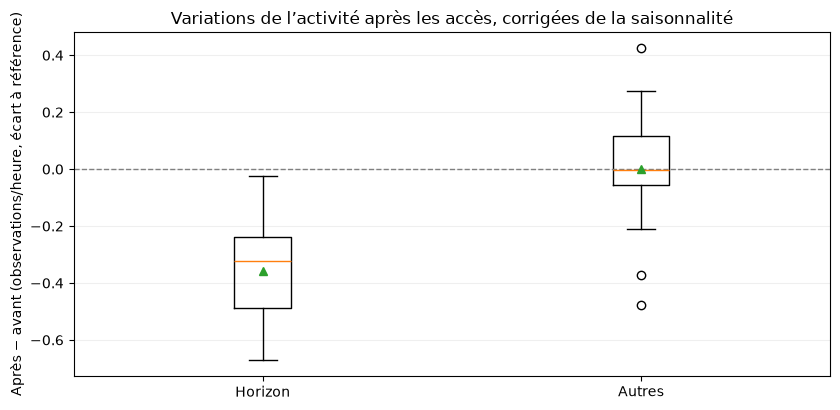

**Résultats.** Parmi les **39 accès avec fenêtre complète**, **13 concernent Horizon**. Leur variation médiane corrigée de la saisonnalité est d'environ **−0,322 observation/heure**, contre **−0,002** pour les 26 autres. Le contrôle avec des sites similaires repose sur **37 accès (11 Horizon)** et met aussi en évidence certaines différences négatives, notamment à KNT-KES.

**Limites.** Les organisations n'interviennent pas sur des sites interchangeables : saison, météo, pesticides, capteurs et interventions répétées peuvent jouer. `EFR-510088` évoque des traces compatibles avec une manipulation d'animaux, mais comporte aussi une incohérence de date. **La causalité n'est pas établie.**

## Enquête 5 — Logistique, réceptions et flux sensibles

**Question.** Quels parcours de marchandises et quelles incohérences comptables ressortent des fichiers logistiques ?

**Méthodes techniques.** La liaison **commande–réception est établie**, mais aucune clé fiable ne permet de poursuivre systématiquement de la réception à l’expédition. Les commandes et réceptions sont jointes sur **`(purchase_order_number, purchase_order_line)`**, avec validation `one_to_one` et comparaison **uniquement à unité identique**. Les stocks sont contrôlés par l'équation simplifiée `stock final = stock initial + entrées − sorties − consommation − pertes déclarées`. Les valeurs atypiques sont étudiées par **IQR**. Dans l'enquête individuelle, les flux sont modélisés en **graphes pondérés** (centralités et communautés de **Louvain**), et plusieurs méthodes du cours sont expérimentées : **`StandardScaler`, `PCA`, `KMeans` et `silhouette_score`, `DBSCAN`, `NearestNeighbors` et `LocalOutlierFactor` de scikit-learn** pour les profils/anomalies ; **Apriori (mlxtend)** pour les règles d'association (**support ≥ 8 %, confiance ≥ 60 %, lift > 1,2**) ; **analyse de processus** et **`TfidfVectorizer` de scikit-learn** en complément. Sur les trente établissements, **K-Means scikit-learn retient K = 2 (silhouette 0,679, groupes 26/4)** ; la PCA conserve 91,4 % de variance sur deux axes. Les expéditions `2-8C` et `frozen` sont confrontées aux capacités déclarées des installations, pas à des relevés de température mesurés.

**Dans ce rapport :** jointure commandes–réceptions, écarts de stocks et principales arêtes du réseau. Les expériences avancées sont documentées dans `investigations/05_logistique/05_logistique.ipynb` ; nos cellules utilisent directement les CSV officiels, sans dépendre de fichiers nettoyés locaux.

**Tableau — Rapprochement des commandes et des réceptions**

| Lignes de commande | Avec réception | Sans réception | Quantités comparables | Réceptions inférieures | Écart médian des partielles (%) |
| --- | --- | --- | --- | --- | --- |
| 650 | 610 | 40 | 610 | 65 | 13.0 |

**Figure — Réceptions partielles : répartition des écarts de quantité**

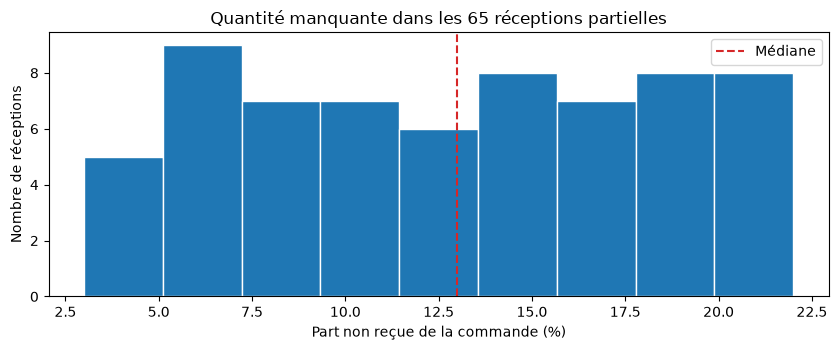

Relevés de stock : 500  
Écarts à l’équation simplifiée : 497  
Soldes théoriques négatifs : 39  
Expéditions : 450 — à 2–8 °C : 103 — congelées : 4 — total à température contrôlée : 107

**Tableau — Principaux flux entre partenaires logistiques**

| Trajet | Envois |
| --- | --- |
| BP-30078 → BP-30021 | 56 |
| BP-30056 → BP-30078 | 33 |
| BP-30078 → BP-30056 | 15 |
| BP-30035 → BP-30042 | 2 |
| BP-30046 → BP-30078 | 2 |
| BP-30049 → BP-30078 | 2 |
| BP-30051 → BP-30064 | 2 |
| BP-30052 → BP-30008 | 2 |

**Résultats et interprétation.** Parmi **650 lignes de commande**, **610** ont une réception et **65** présentent une quantité inférieure à la commande (médiane **13 %** manquants). Une méthode IQR par catégorie et unité identifie **5 quantités atypiques d’expéditions**, distinctes des **9 prix unitaires atypiques des commandes**. L'équation simplifiée produit **497 écarts pour 500 relevés de stock**. Les flux sont concentrés sur certains partenaires et **107 expéditions** sont déclarées à température contrôlée. Parmi les **52 expéditions d’échantillons biologiques**, **52/52** sont à `2-8c` ; parmi les **103 expéditions à `2-8c`**, seules **52/103 (50,5 %)** contiennent des échantillons biologiques. Le bureau `FCL-1011` est déclaré avec une capacité de stockage `ambient`, **sans `2-8C` ni `frozen` mentionnés**, bien qu’il soit l’origine de **43 transports à température contrôlée**.

**Limites.** La formule de stock ne reprend pas nécessairement toutes les opérations ; elle ne prouve **ni pertes physiques ni disparition de prélèvements biologiques**. Les données ne relient pas directement chaque commande à un envoi et n'incluent pas de mesures réelles de température : il serait incorrect d'en déduire des détournements ou des violations de conservation.

## Enquête 6 — Documents, références et signaux

**Question.** Quels documents rassemblent les mêmes thèmes, et leurs références peuvent-elles être rapprochées des autres fichiers ?

**Méthodes techniques.** Sur **130 documents**, l'enquête individuelle applique un prétraitement **NLP** (minuscules, tokenisation, suppression de ponctuation et de mots vides), des **fréquences de termes et n-grammes**, puis une représentation **TF-IDF** (**unigrammes/bigrammes, 1 000 variables maximum, `min_df=2`, `max_df=0.90`**). Les documents sont regroupés par **K-Means**, avec **K = 2 à 8 comparés par score de silhouette** (K = 7 retenu), puis projetés par **PCA 2D** pour visualisation. L'extraction d'identifiants par **expressions régulières** et les colonnes de référence permettent des contrôles de jointure ; la **cooccurrence des entités** produit un graphe. Les **44 signaux cardiaques** sont résumés (RMS, étendue, croisements de zéro, rythme estimé) puis standardisés et groupés par K-Means (**K = 2** dans l'étude individuelle).

**Dans ce rapport :** vérification des corpus, documents pivots et mots-clés. Le clustering complet et les 96 925 échantillons cardiaques sont traités dans `06_textes_et_signaux.ipynb`.

Documents : 130

**Tableau — Répartition des documents par corpus**

| origine | documents |
| --- | --- |
| clinique | 30 |
| ecologie | 30 |
| institutionnel | 30 |
| public | 40 |

**Tableau — Documents pivots de l'enquête**

| document_id | origine | titre_affiche |
| --- | --- | --- |
| PUB-510043 | public | Letter from the Vosmere Commercial Papers |
| PUB-510033 | public | Extract from the Eastern Orchard Programme Min... |
| PUB-510079 | public | Message Concerning Collected Eonycteris |
| PUB-510063 | public | Restricted Classification and External-Transfe... |
| PUB-510076 | public | Catalog Note on Recurrent Historical Identifiers |
| MEM-510100 | institutionnel | Secure Delivery Record-Handling Instruction |
| MEM-510101 | institutionnel | Restricted CHAMELEO Governance Review |
| CLN-510027 | clinique | Targeted Thoracic Imaging Review |
| CLN-510025 | clinique | Restricted Phenotype and Public-Identity Resol... |
| EFR-510088 | ecologie | Post-Access Ecological Incident at KNT-KES |

**Tableau — Termes du narratif retrouvés dans les documents**

| Expression | public | institutionnel | clinique | ecologie |
| --- | --- | --- | --- | --- |
| CHAMELEO | 1 | 3 | 0 | 0 |
| Unwabu | 1 | 1 | 0 | 0 |
| Eonycteris | 1 | 0 | 0 | 1 |
| Chamaeleonidian | 2 | 0 | 0 | 0 |
| Wren Street | 2 | 0 | 0 | 0 |

**Figure — Présence des termes du narratif dans les quatre corpus textuels**

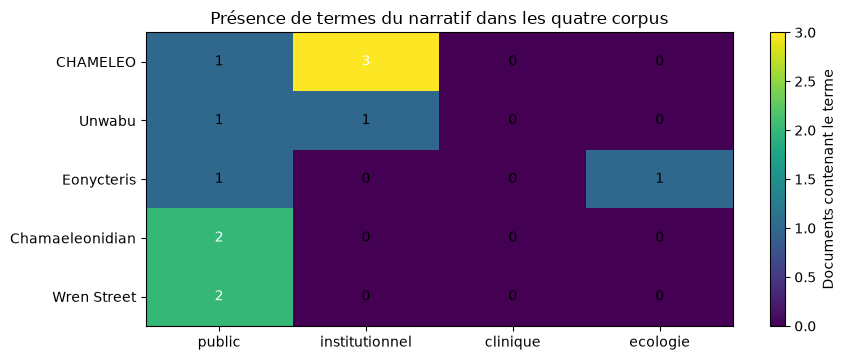

**Résultats.** L'enquête individuelle identifie **sept clusters textuels** : la plupart séparent des types de documents, tandis qu'un petit ensemble transversal rapproche notamment identité, physiologie et historique. Les documents clés sont `MEM-510100` (annexes restreintes), `MEM-510101` (pont administratif **Unwabu–CHAMELEO–Meridian**), `PUB-510079` (témoignage sur *Eonycteris*) et `PUB-510063` (terme *Chamaeleonidian*).

**Limites.** Le regroupement lexical ne prouve ni collaboration ni véracité des textes. Notre tableau de mots-clés ne remplace pas le modèle TF-IDF–K-Means de l'enquête individuelle. Dans son validateur, cinq références `ACC-...` ont été recherchées dans la table `REG` : elles existent bien dans `site_access_case_events.csv`. **Le notebook 06 devra être harmonisé avec ce résultat avant le dépôt final**, sans changer l'interprétation des documents.

# Partie II — Nos recoupements et le secret proposé

Les enquêtes séparées ont fait apparaître des anomalies et des documents intéressants. Nous cherchons maintenant **ce qui les relie réellement**, puis ce que ces rapprochements permettent d'imaginer dans le récit fictif.

## 3. Accès nocturnes et expéditions biologiques

Notre rapprochement le plus régulier concerne **18 accès nocturnes réalisés par Horizon**. Le même jour, **six heures après la fin de chacun**, une expédition biologique Horizon → Meridian est enregistrée, avec une température déclarée de **2–8 °C**.

La jointure exploite la date et les codes des partenaires. **Elle ne repose pas sur un identifiant commun entre accès et expédition.** Nous comparons ensuite ces mêmes expéditions aux accès des autres demandeurs, sans prétendre vérifier l'ensemble de leurs flux biologiques.

Accès Horizon terminés : 18  
Expéditions biologiques Horizon vers Meridian : 20  
Correspondances le même jour : 18  
Délais observés (heures) : 6 heures  
Températures déclarées : {'2-8C': 18}

**Tableau — Exemples des correspondances d'accès et d'expédition**

| Dossier d'accès | Site | Fin de l'accès | Expédition | Départ | Délai (h) |
| --- | --- | --- | --- | --- | --- |
| ACC-2018-0001 | TMB-NAC | 2018-02-16 03:00:00 | SHP-2018-00004 | 2018-02-16 09:00:00 | 6.0 |
| ACC-2018-0002 | KNT-KES | 2018-03-23 03:00:00 | SHP-2018-00007 | 2018-03-23 09:00:00 | 6.0 |
| ACC-2018-0003 | AVL-MAR | 2018-05-25 03:00:00 | SHP-2018-00032 | 2018-05-25 09:00:00 | 6.0 |
| ACC-2019-0004 | TMB-PEL | 2019-08-09 03:00:00 | SHP-2019-00009 | 2019-08-09 09:00:00 | 6.0 |
| ACC-2019-0005 | KNT-LUM | 2019-09-13 03:00:00 | SHP-2019-00026 | 2019-09-13 09:00:00 | 6.0 |
| ACC-2019-0006 | AVL-VEL | 2019-11-08 03:00:00 | SHP-2019-00041 | 2019-11-08 09:00:00 | 6.0 |
| ACC-2020-0007 | KNT-SEN | 2020-04-10 03:00:00 | SHP-2020-00019 | 2020-04-10 09:00:00 | 6.0 |
| ACC-2020-0008 | AVL-ORR | 2020-06-12 03:00:00 | SHP-2020-00038 | 2020-06-12 09:00:00 | 6.0 |
| ACC-2021-0009 | KNT-KES | 2021-03-26 03:00:00 | SHP-2021-00007 | 2021-03-26 09:00:00 | 6.0 |
| ACC-2021-0010 | AVL-MAR | 2021-05-21 03:00:00 | SHP-2021-00028 | 2021-05-21 09:00:00 | 6.0 |

**Figure — Répartition annuelle des correspondances Horizon–Meridian**

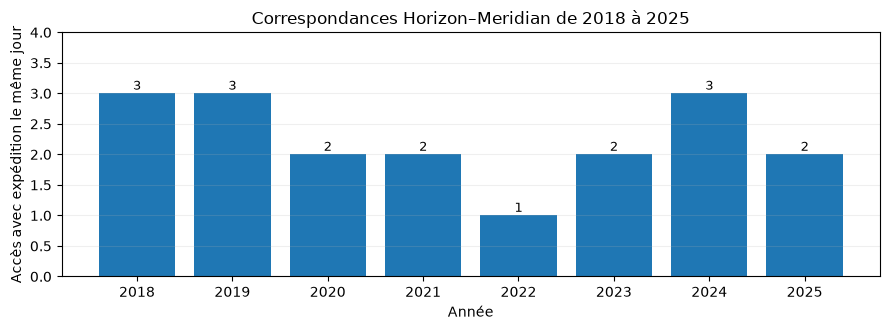

**Tableau — Comparaison avec les 36 autres accès terminés**

| Groupe | acces_termines | coincidences_avec_flux_horizon_meridian |
| --- | --- | --- |
| Autres demandeurs | 36 | 0 |
| Horizon | 18 | 18 |

Expéditions Horizon–Meridian biologiques sans accès Horizon le même jour : 2

**Contrôle comparatif.** Parmi les **54 accès terminés**, 18 concernent Horizon et 36 d'autres demandeurs. **Aucun des 36 autres accès terminés ne coïncide le même jour avec une expédition biologique Horizon–Meridian.** Cela ne signifie pas que les autres organisations n'ont pas de flux biologiques : seuls ces envois particuliers ont été recherchés.

Deux expéditions biologiques Horizon–Meridian n'ont pas d'accès Horizon terminé à la même date. La répétition des 18 correspondances est forte, mais reste **temporelle**.

**Ce qui est établi :** 18 correspondances par dates, partenaires et catégorie de marchandise, toutes à six heures d'intervalle. **Ce qui ne l'est pas :** l'origine physique des colis, leur contenu exact et leur destination finale.

À **KNT-KES**, on retrouve ce schéma en **2018, 2021 et 2024**. Ces exemples nous ont incités à confronter les flux aux observations écologiques.

## 4. Le rapprochement avec l'écologie

Les **39 accès étudiables** montrent des variations hétérogènes, mais celles associées à Horizon sont plus négatives après correction saisonnière. Sur les **37 accès disposant de sites comparables**, dont **11 Horizon**, certains contrastes persistent, notamment à **KNT-KES**.

Le rapport `EFR-510088` mentionne des traces de manipulation et une baisse d'activité d'*Eonycteris spelaea*. Il ne désigne pas de responsable et comporte une discordance de dates. **Ces éléments justifient une enquête, pas l'affirmation d'un prélèvement.**

## 5. Registres et santé : une autre piste

Les archives signalent des **successions d'organisations** et des licences utilisées bien après leur délivrance, notamment celle d'**Emil Warden**. Sur le versant médical, deux acquisitions de `PAT-31065` montrent des périodicités différentes. `CLN-510027` évoque deux sources de contraction possibles, sans diagnostic définitif.

`CLN-510025` propose un rapprochement administratif du patient avec **Elias Voss**, mais les années de naissance ne correspondent pas (**1975 / 1961**). `PUB-510045` décrit des interventions confidentielles récurrentes chez plusieurs dirigeants. Cela nourrit l'hypothèse d'un suivi réservé, **sans lien démontré avec les cargaisons biologiques**.

## 6. Les documents qui éclairent le récit

Le regroupement des **130 textes en sept groupes** permet d'orienter la lecture. Parmi les documents les plus utiles :

- `MEM-510100` décrit les **annexes de transport restreintes** ; `MEM-510101` relie l'autorité **Unwabu**, le code **CHAMELEO** et la direction **Meridian**.
- `PUB-510079` est un **témoignage** sur la collecte d'*Eonycteris spelaea* et une possible destination à la **consommation**.
- `PUB-510063` utilise **Chamaeleonidian** pour une population présentée comme non humaine et évoque des transferts « non terrestres », **sans route ni destination établies**.
- `PUB-510094` distingue deux orientations opposées sur l'exploitation des ressources et la divulgation, avec **Jacob Vale** associé à la position anti-extraction.

Une formule attire notre attention : **« make the conditions ordinary »**, relevée dans le catalogue `PUB-510076`. Une lettre de **1942** (`PUB-510043`) et un compte rendu de **1962** (`PUB-510033`) reprennent des formulations proches. Nous l'interprétons comme l'idée de **banaliser des opérations inhabituelles** pour qu'elles passent inaperçues.

Ces documents restent des **sources à confronter**, pas des confirmations automatiques. Dans d'autres textes, certains termes sont employés dans un sens métaphorique ou technique différent.

## 7. Contrôle des références citées

Nous vérifions les identifiants dans leur table d'origine : les dossiers `REG-...` dans le journal réglementaire, les accès `ACC-...` dans le journal des accès. Les **cinq références `ACC`** initialement signalées comme introuvables existent bien dans la bonne table. Ce contrôle rectifie leur **existence documentaire**, sans valider les événements racontés dans les textes.

**Tableau — Vérification des cinq références ACC dans leur table d'origine**

| Référence | Retrouvée dans site_access_case_events.csv |
| --- | --- |
| ACC-2019-0005 | True |
| ACC-2018-0024 | True |
| ACC-2023-0047 | True |
| ACC-2020-0008 | True |
| ACC-2023-0028 | True |

Correspondances retrouvées : 5 / 5

## 8. L'hypothèse qui relie nos découvertes

Dans le **récit fictif**, une population cachée pourrait vivre parmi les humains sous des identités successives. `PUB-510063` emploie à son sujet le terme **Chamaeleonidian** : **une espèce de « caméléons » ?** C'est une interprétation possible du nom, non une classification biologique démontrée.

Un réseau organisé autour de **Meridian BioLogistics**, du code **CHAMELEO** et de l'autorité **Unwabu** assurerait discrètement l'approvisionnement en matériel biologique. Les accès nocturnes d'**Horizon** et les expéditions correspondantes constitueraient un élément de cette organisation. Un témoin évoque l'utilisation d'une partie des chauves-souris *Eonycteris spelaea* pour la consommation ; certains établissements médicaux, dont **Asterion**, pourraient assurer un suivi confidentiel.

Les archives suggèrent enfin **deux orientations opposées** sur les ressources et la divulgation, avec **Jacob Vale** associé à la position anti-extraction. La formule **« make the conditions ordinary »** nous semble résumer le mécanisme de dissimulation imaginé : donner à l'exceptionnel l'apparence de l'ordinaire.

**Il s'agit de notre lecture du narratif, pas de liens tous démontrés par les données.**

## 9. Les principales limites

- Les **18 correspondances** Horizon–Meridian sont temporelles : aucune clé ne relie directement un accès au contenu d'un colis ou à son usage.
- Le témoignage sur la consommation et les **écarts d'inventaire** ne démontrent pas que des animaux précis ont été prélevés ou consommés.
- Les **identités successives** ne sont pas prouvées ; les deux rythmes cardiaques de `PAT-31065` ne constituent pas un diagnostic d'anatomie non humaine, et les dates de naissance divergent.
- Certains documents présentent des **incohérences chronologiques** (`EFR-510088`, `REG-2023-0008`).
- Les éventuels transferts « non terrestres » restent une hypothèse documentaire, sans trajet ni destination établis.

Nous séparons donc **faits mesurés**, **affirmations des documents** et **hypothèses**.

## 10. Notre conclusion collective

Les six études convergent vers un scénario possible : **un programme restreint CHAMELEO–Meridian** dissimulerait, derrière des procédures administratives, écologiques, médicales et logistiques ordinaires, un réseau d'approvisionnement biologique et une population décrite dans les archives comme **Chamaeleonidian**.

Le résultat quantitatif le plus net reste la répétition de **18 accès Horizon suivis six heures plus tard de 18 expéditions biologiques vers Meridian**. En revanche, **aucun des 36 autres accès terminés ne coïncide le même jour avec une expédition biologique Horizon–Meridian** ; cette comparaison ne porte pas sur leurs autres transports.

La formule **« make the conditions ordinary »** (`PUB-510076`, `PUB-510043`, `PUB-510033`) résume notre interprétation : rendre habituelles des opérations exceptionnelles. Nous envisageons ainsi des **identités successives**, des **soins confidentiels** et un usage particulier d'*Eonycteris*, sans pouvoir prouver leur lien matériel exact ni l'éventuelle destination des transferts non terrestres.

**Notre secret est donc une reconstruction cohérente d'indices concordants, et non une certitude sur chacun des éléments du récit.**

## Sources de travail et transparence sur l'usage de l'IA

Les méthodes et les figures détaillées figurent dans les enquêtes individuelles :

- [D1 — Dossiers et coordination](01_dossiers_et_coordination.ipynb)
- [D2 — Registres et réseau](02_registres_et_reseau.ipynb)
- [D3 — Santé](03_sante.ipynb)
- [D4 — Écologie](notebooks/04_ecologie_analyse.ipynb) et [nettoyage écologique](notebooks/04_ecology_cleaning.ipynb)
- [D5 — Logistique](investigations/05_logistique/05_logistique.ipynb)
- [D6 — Textes et signaux](06_textes_et_signaux.ipynb)

### Déclaration d'assistance par IA générative

Dans ce projet, des outils d'IA générative ont été employés comme **assistance**, notamment pour :

- **La présentation et la rédaction :** organiser le notebook collectif, proposer des formulations, simplifier ou clarifier des explications et homogénéiser la mise en page.
- **La compréhension des méthodes et des résultats :** expliquer des notions (par exemple TF-IDF, K-Means, silhouette, PCA), aider à interpréter certaines sorties et à distinguer observation, hypothèse et limite.
- **Le code :** proposer, compléter et adapter des cellules Python (y compris par autocomplétion assistée), rechercher des erreurs et aider au débogage. L'assistance ne se limite donc pas à la seule autocomplétion ; les résultats retenus dans ce rapport proviennent de calculs exécutés sur les données du projet.
- **Des vérifications ciblées :** une aide a aussi été apportée à l'examen des critères et à la formulation de jugements sur l'échantillon de **30 paires de résolution d'identité** de la partie 2. Le statut de cette vérification doit être présenté avec prudence : une appréciation assistée ne constitue pas, à elle seule, une validation humaine indépendante.